# 🔬 Lab Task 02 — Effect of Image Filtering on Skin-Lesion Classification
### HAM10000 Dataset | EfficientNet-B3 · ResNet-50 · DenseNet-121
**Student:** Muhammad Majid Ali | FA23-BAI-045 | Quantum Coders

---
**Experiment matrix:** 3 pretrained models × 6 filter conditions = **18 experiments**


In [ ]:
# SECTION 1 ── Install Dependencies
!pip install -q kagglehub torch torchvision scikit-learn matplotlib seaborn pandas tqdm opencv-python-headless
print("✅ All packages installed")


✅ All packages installed


## 📦 Section 2 — Dataset Download (kagglehub)

In [ ]:
import kagglehub, os, shutil

# Download dataset
path = kagglehub.dataset_download("surajghuwalewala/ham1000-segmentation-and-classification")
print("Path to dataset files:", path)

# List what's inside
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 2:
        subindent = ' ' * 2 * (level + 1)
        for f in files[:5]:
            print(f'{subindent}{f}')
        if len(files) > 5:
            print(f'{subindent}... ({len(files)} files total)')


100%|██████████| 2.59G/2.59G [00:30<00:00, 91.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2
2/
  GroundTruth.csv
  images/
    ISIC_0025717.jpg
    ISIC_0024457.jpg
    ISIC_0027835.jpg
    ISIC_0032213.jpg
    ISIC_0033479.jpg
    ... (10017 files total)
  masks/
    ISIC_0027706_segmentation.png
    ISIC_0031998_segmentation.png
    ISIC_0027739_segmentation.png
    ISIC_0029882_segmentation.png
    ISIC_0028417_segmentation.png
    ... (10015 files total)


## ⚙️ Section 3 — Imports & Global Config

In [ ]:
import os, random, warnings, glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    efficientnet_b3, EfficientNet_B3_Weights,
    resnet50,        ResNet50_Weights,
    densenet121,     DenseNet121_Weights,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    balanced_accuracy_score, classification_report,
)
from sklearn.preprocessing import label_binarize
from tqdm import tqdm

warnings.filterwarnings("ignore")

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
set_seed()

# ── Hyper-parameters ───────────────────────────────────────────────────────────
IMG_SIZE    = 224
BATCH_SIZE  = 32
EPOCHS      = 15
LR          = 1e-4
WEIGHT_DECAY= 1e-4
NUM_CLASSES = 7

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
print(f"CUDA   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")


Device : cuda
CUDA   : True
GPU    : Tesla T4


## 📁 Section 4 — Path Setup

In [ ]:
# ── Auto-detect paths from kagglehub download ─────────────────────────────────
import kagglehub
BASE_PATH = kagglehub.dataset_download("surajghuwalewala/ham1000-segmentation-and-classification")

# Find images folder (contains .jpg files)
IMG_DIR = None
CSV_PATH = None

for root, dirs, files in os.walk(BASE_PATH):
    jpgs = [f for f in files if f.endswith('.jpg')]
    csvs = [f for f in files if f.endswith('.csv')]
    if jpgs and IMG_DIR is None:
        IMG_DIR = root
        print(f"✅ Images found at : {IMG_DIR}  ({len(jpgs)} jpg files)")
    if csvs and CSV_PATH is None:
        CSV_PATH = os.path.join(root, csvs[0])
        print(f"✅ CSV found at    : {CSV_PATH}")

assert IMG_DIR  is not None, "Could not find image directory!"
assert CSV_PATH is not None, "Could not find metadata CSV!"

# ── Class maps ────────────────────────────────────────────────────────────────
CLASS_NAMES = {'akiec':0,'bcc':1,'bkl':2,'df':3,'mel':4,'nv':5,'vasc':6}
IDX_TO_CLASS = {v:k for k,v in CLASS_NAMES.items()}
CLASS_FULL  = {
    'akiec':'Actinic Keratoses','bcc':'Basal Cell Carcinoma',
    'bkl':'Benign Keratosis',  'df':'Dermatofibroma',
    'mel':'Melanoma',           'nv':'Melanocytic Nevi',
    'vasc':'Vascular Lesions',
}


✅ CSV found at    : /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2/GroundTruth.csv
✅ Images found at : /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2/images  (10015 jpg files)


## 📊 Section 5 — Load Metadata & EDA

In [ ]:
df_raw = pd.read_csv(CSV_PATH)
print("CSV columns:", df_raw.columns.tolist())
print(df_raw.head())

# ── One-hot encoded CSV (columns: image, MEL, NV, BCC, AKIEC, BKL, DF, VASC)
# ── Map one-hot column names → CLASS_NAMES keys ───────────────────────────────
ONEHOT_TO_KEY = {
    'MEL':'mel', 'NV':'nv', 'BCC':'bcc',
    'AKIEC':'akiec', 'BKL':'bkl', 'DF':'df', 'VASC':'vasc',
}

onehot_cols = [c for c in df_raw.columns if c.upper() in ONEHOT_TO_KEY]

if onehot_cols:
    # Convert one-hot → single 'dx' label string per row
    def decode_onehot(row):
        for col in onehot_cols:
            if row[col] == 1.0:
                return ONEHOT_TO_KEY[col.upper()]
        # fallback: argmax handles soft/float labels
        return ONEHOT_TO_KEY[row[onehot_cols].idxmax().upper()]

    df_raw['dx'] = df_raw.apply(decode_onehot, axis=1)
    print("\n✅ One-hot decoded → 'dx' column created")

elif 'dx' in df_raw.columns:
    pass  # already correct format

elif 'label' in df_raw.columns:
    df_raw['dx'] = df_raw['label']

else:
    raise ValueError(f"Unrecognised CSV format. Columns: {df_raw.columns.tolist()}")

# ── Map dx string → integer index ─────────────────────────────────────────────
df_raw['label_idx'] = df_raw['dx'].map(CLASS_NAMES)

# ── Detect image ID column (could be 'image' or 'image_id') ───────────────────
ID_COL = 'image'    if 'image'    in df_raw.columns else \
         'image_id' if 'image_id' in df_raw.columns else \
         df_raw.columns[0]
print(f"Image ID column : {ID_COL}")

# ── Find each image file on disk ───────────────────────────────────────────────
def find_img(image_id):
    for ext in ['.jpg', '.png', '.JPG', '.PNG']:
        p = os.path.join(IMG_DIR, str(image_id) + ext)
        if os.path.exists(p):
            return p
    return None

df_raw['filepath'] = df_raw[ID_COL].apply(find_img)
df = df_raw.dropna(subset=['filepath', 'label_idx']).reset_index(drop=True)

print(f"\n✅ Total usable images : {len(df)}")
print("\nClass distribution:")
print(df['dx'].value_counts())

CSV columns: ['image', 'MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']
          image  MEL   NV  BCC  AKIEC  BKL   DF  VASC
0  ISIC_0024306  0.0  1.0  0.0    0.0  0.0  0.0   0.0
1  ISIC_0024307  0.0  1.0  0.0    0.0  0.0  0.0   0.0
2  ISIC_0024308  0.0  1.0  0.0    0.0  0.0  0.0   0.0
3  ISIC_0024309  0.0  1.0  0.0    0.0  0.0  0.0   0.0
4  ISIC_0024310  1.0  0.0  0.0    0.0  0.0  0.0   0.0

✅ One-hot decoded → 'dx' column created
Image ID column : image

✅ Total usable images : 10015

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


### Class Distribution

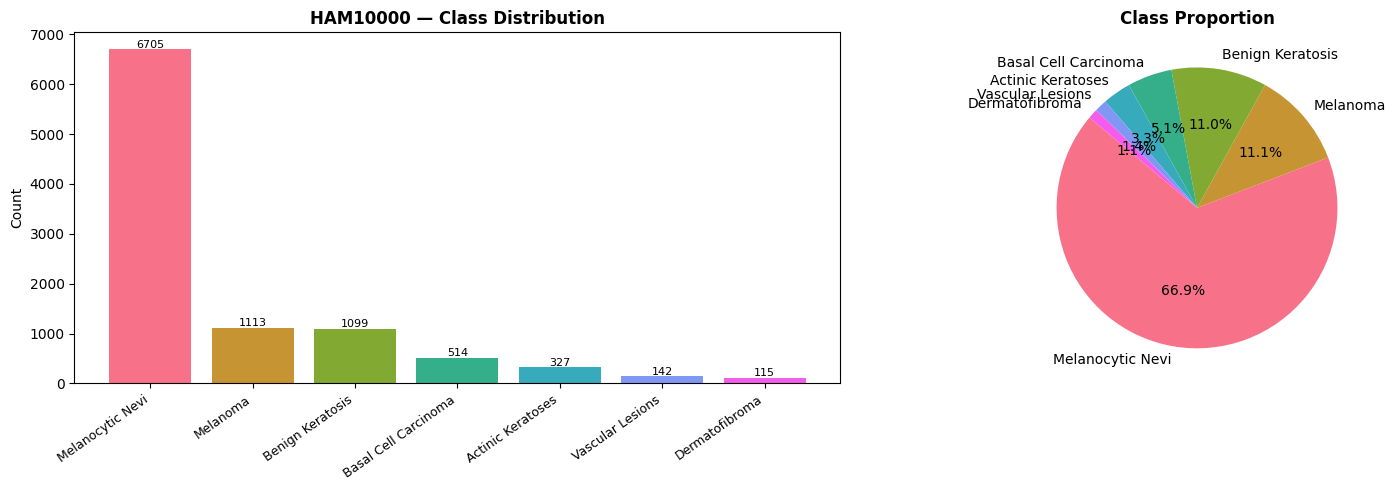

✅ Saved: class_distribution.png


In [ ]:
counts = df['dx'].value_counts()
labels_full = [CLASS_FULL[k] for k in counts.index]

fig, axes = plt.subplots(1, 2, figsize=(16,5))
pal = sns.color_palette("husl", len(counts))

axes[0].bar(range(len(counts)), counts.values, color=pal)
axes[0].set_xticks(range(len(counts)))
axes[0].set_xticklabels(labels_full, rotation=35, ha='right', fontsize=9)
axes[0].set_title("HAM10000 — Class Distribution", fontweight='bold')
axes[0].set_ylabel("Count")
for i,v in enumerate(counts.values):
    axes[0].text(i, v+30, str(v), ha='center', fontsize=8)

axes[1].pie(counts.values, labels=labels_full,
            autopct='%1.1f%%', colors=pal, startangle=140)
axes[1].set_title("Class Proportion", fontweight='bold')
plt.tight_layout(); plt.savefig("class_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: class_distribution.png")


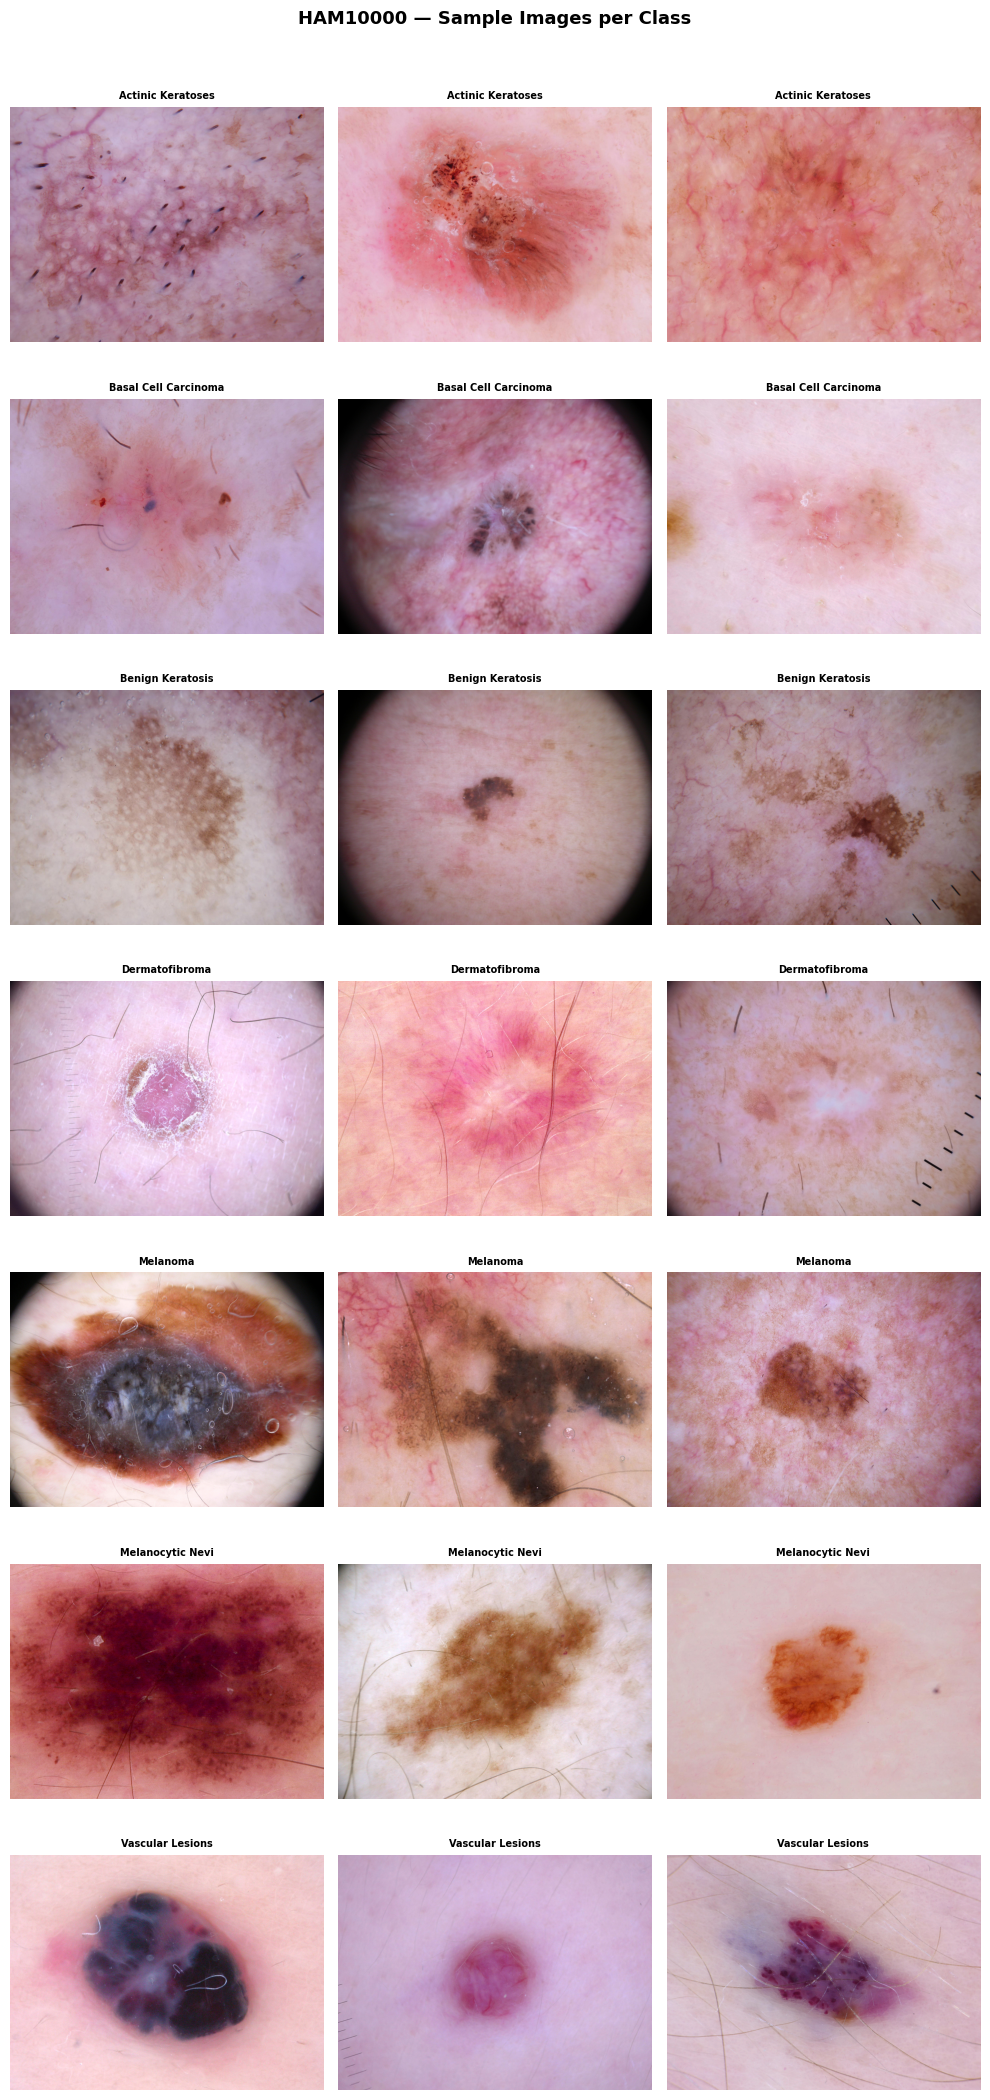

In [ ]:
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(10, NUM_CLASSES*3))
for i, (cls, idx) in enumerate(CLASS_NAMES.items()):
    subset = df[df['dx']==cls].sample(min(3, (df['dx']==cls).sum()), random_state=SEED)
    for j, (_, row) in enumerate(subset.iterrows()):
        img = cv2.cvtColor(cv2.imread(row['filepath']), cv2.COLOR_BGR2RGB)
        axes[i][j].imshow(img)
        axes[i][j].set_title(CLASS_FULL[cls], fontsize=7, fontweight='bold')
        axes[i][j].axis('off')
plt.suptitle("HAM10000 — Sample Images per Class", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("sample_images.png", dpi=150, bbox_inches='tight')
plt.show()


## 🎨 Section 6 — Image Filters

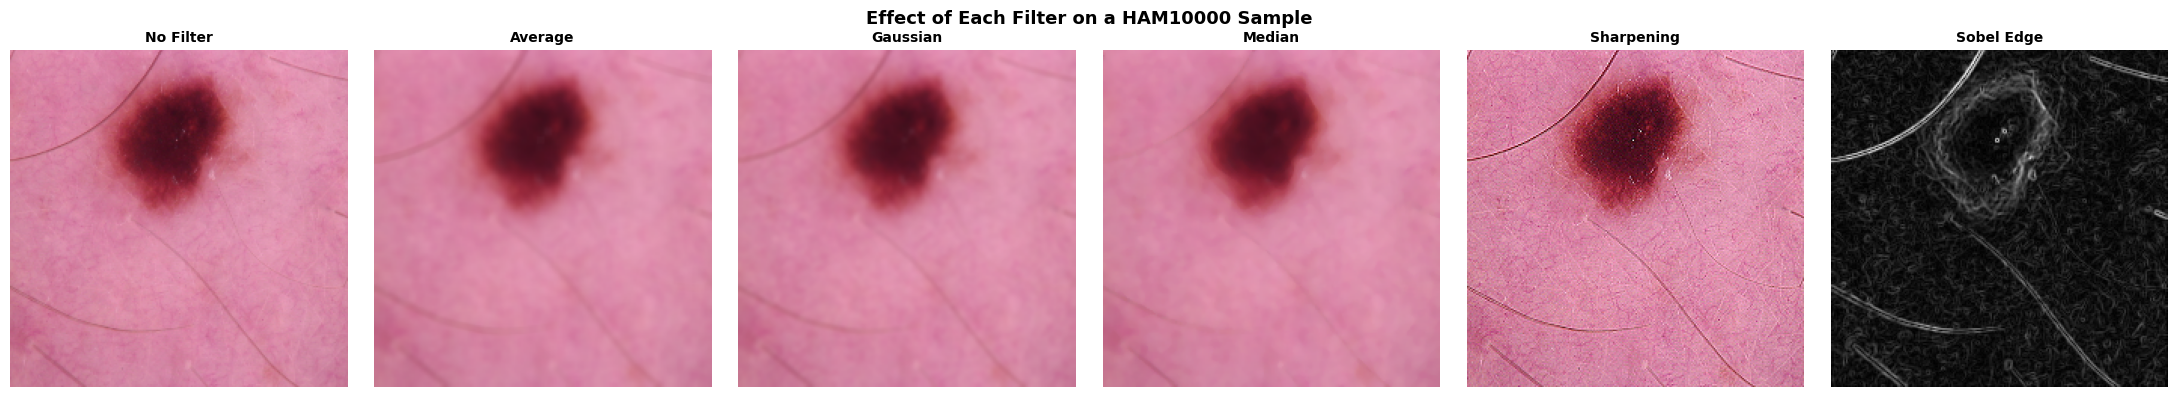

✅ Saved: filter_examples.png


In [ ]:
FILTER_NAMES  = ["none","average","gaussian","median","sharpening","sobel"]
FILTER_LABELS = {
    "none":"No Filter","average":"Average","gaussian":"Gaussian",
    "median":"Median","sharpening":"Sharpening","sobel":"Sobel Edge"
}

def apply_filter(img_rgb: np.ndarray, fname: str) -> np.ndarray:
    if fname == "none":
        return img_rgb
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    if fname == "average":
        out = cv2.blur(bgr, (5,5))
    elif fname == "gaussian":
        out = cv2.GaussianBlur(bgr, (5,5), sigmaX=1.5)
    elif fname == "median":
        out = cv2.medianBlur(bgr, 5)
    elif fname == "sharpening":
        k   = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], dtype=np.float32)
        out = np.clip(cv2.filter2D(bgr,-1,k), 0, 255).astype(np.uint8)
    elif fname == "sobel":
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        sx   = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sy   = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        mag  = np.sqrt(sx**2+sy**2)
        mag  = np.clip(mag/mag.max()*255, 0, 255).astype(np.uint8)
        out  = cv2.cvtColor(mag, cv2.COLOR_GRAY2BGR)
    else:
        raise ValueError(f"Unknown filter: {fname}")
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

# ── Visualise all filters on one sample ───────────────────────────────────────
sample_path = df.sample(1, random_state=SEED).iloc[0]['filepath']
orig        = cv2.resize(cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB),
                         (IMG_SIZE, IMG_SIZE))

fig, axes = plt.subplots(1, 6, figsize=(22, 4))
for ax, fn in zip(axes, FILTER_NAMES):
    ax.imshow(apply_filter(orig, fn))
    ax.set_title(FILTER_LABELS[fn], fontweight='bold', fontsize=10)
    ax.axis('off')
plt.suptitle("Effect of Each Filter on a HAM10000 Sample", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("filter_examples.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: filter_examples.png")


## 🗄️ Section 7 — Dataset Class & DataLoaders

In [ ]:
EVAL_TF = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

TRAIN_AUG = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

class HAM10000Dataset(Dataset):
    def __init__(self, df, filter_name="none", augment=False):
        self.df          = df.reset_index(drop=True)
        self.filter_name = filter_name
        self.augment     = augment

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = cv2.cvtColor(cv2.imread(row['filepath']), cv2.COLOR_BGR2RGB)
        img   = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img   = apply_filter(img, self.filter_name)
        label = int(row['label_idx'])
        tf    = TRAIN_AUG if self.augment else EVAL_TF
        return tf(img), label

def make_sampler(df):
    counts = df['label_idx'].value_counts().sort_index()
    wts    = 1.0 / counts.values
    sw     = [wts[int(l)] for l in df['label_idx']]
    return torch.utils.data.WeightedRandomSampler(sw, len(sw), replacement=True)

def make_loaders(df_train, df_val, filter_name):
    train_ds = HAM10000Dataset(df_train, filter_name, augment=True)
    val_ds   = HAM10000Dataset(df_val,   filter_name, augment=False)
    sampler  = make_sampler(df_train)
    train_ld = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=2, pin_memory=True)
    val_ld   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
    return train_ld, val_ld

# ── Stratified 80/20 split (same for all experiments) ────────────────────────
df_train, df_val = train_test_split(df, test_size=0.20,
                                    random_state=SEED, stratify=df['label_idx'])
print(f"Train: {len(df_train)}  |  Val: {len(df_val)}")


Train: 8012  |  Val: 2003


## 🧠 Section 8 — Model Definitions

In [ ]:
MODEL_NAMES   = ["efficientnet_b3", "resnet50", "densenet121"]
MODEL_DISPLAY = {
    "efficientnet_b3":"EfficientNet-B3",
    "resnet50":       "ResNet-50",
    "densenet121":    "DenseNet-121",
}

def build_model(name):
    if name == "efficientnet_b3":
        m = efficientnet_b3(weights=EfficientNet_B3_Weights.IMAGENET1K_V1)
        in_f = m.classifier[1].in_features
        m.classifier = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(in_f,512), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(512, NUM_CLASSES))
    elif name == "resnet50":
        m = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        in_f = m.fc.in_features
        m.fc = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(in_f,512), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(512, NUM_CLASSES))
    elif name == "densenet121":
        m = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
        in_f = m.classifier.in_features
        m.classifier = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(in_f,512), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(512, NUM_CLASSES))
    else:
        raise ValueError(name)
    return m.to(DEVICE)

print("✅ Model builder ready")
print("Models:", list(MODEL_DISPLAY.values()))


✅ Model builder ready
Models: ['EfficientNet-B3', 'ResNet-50', 'DenseNet-121']


## 🏋️ Section 9 — Training & Evaluation Functions

In [ ]:
def class_weights(df_tr):
    counts = df_tr['label_idx'].value_counts().sort_index().values.astype(float)
    wts    = 1.0 / counts
    wts    = (wts / wts.sum()) * NUM_CLASSES
    return torch.tensor(wts, dtype=torch.float32).to(DEVICE)

def train_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    loss_sum, correct, total = 0., 0, 0
    for imgs, labels in tqdm(loader, leave=False, desc="  train"):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            out  = model(imgs)
            loss = criterion(out, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        loss_sum += loss.item()*imgs.size(0)
        correct  += (out.argmax(1)==labels).sum().item()
        total    += imgs.size(0)
    return loss_sum/total, correct/total

@torch.no_grad()
def eval_epoch(model, loader, criterion):
    model.eval()
    loss_sum, preds_all, labels_all, probs_all = 0., [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        out  = model(imgs)
        loss = criterion(out, labels)
        loss_sum += loss.item()*imgs.size(0)
        probs_all.extend(torch.softmax(out,1).cpu().numpy())
        preds_all.extend(out.argmax(1).cpu().numpy())
        labels_all.extend(labels.cpu().numpy())
    n = len(loader.dataset)
    return (loss_sum/n,
            np.array(preds_all), np.array(labels_all), np.array(probs_all))

def metrics(y_true, y_pred, y_probs):
    y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    try:    auc = roc_auc_score(y_bin, y_probs, multi_class='ovr', average='macro')
    except: auc = float('nan')
    return dict(
        accuracy   = accuracy_score(y_true, y_pred),
        balanced   = balanced_accuracy_score(y_true, y_pred),
        precision  = precision_score(y_true, y_pred, average='macro', zero_division=0),
        recall     = recall_score(y_true, y_pred, average='macro', zero_division=0),
        macro_f1   = f1_score(y_true, y_pred, average='macro', zero_division=0),
        per_cls_f1 = f1_score(y_true, y_pred, average=None,    zero_division=0),
        auc        = auc,
    )

def run_experiment(model_name, filter_name, df_train, df_val, epochs=EPOCHS):
    print(f"\n{'─'*55}")
    print(f"  Model: {MODEL_DISPLAY[model_name]}  |  Filter: {FILTER_LABELS[filter_name]}")
    print(f"{'─'*55}")
    set_seed()
    model     = build_model(model_name)
    cw        = class_weights(df_train)
    criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler    = torch.cuda.amp.GradScaler()
    train_ld, val_ld = make_loaders(df_train, df_val, filter_name)

    history = dict(tl=[], vl=[], ta=[], va=[])
    best_f1, best_wts = 0., None

    for ep in range(1, epochs+1):
        tl, ta = train_epoch(model, train_ld, criterion, optimizer, scaler)
        vl, vp, vlab, vpr = eval_epoch(model, val_ld, criterion)
        m = metrics(vlab, vp, vpr)
        scheduler.step()
        history['tl'].append(tl); history['vl'].append(vl)
        history['ta'].append(ta); history['va'].append(m['accuracy'])
        if m['macro_f1'] > best_f1:
            best_f1  = m['macro_f1']
            best_wts = {k:v.cpu() for k,v in model.state_dict().items()}
        print(f"  Ep {ep:02d}/{epochs} | "
              f"TrLoss {tl:.4f} TrAcc {ta:.4f} | "
              f"VlLoss {vl:.4f} VlAcc {m['accuracy']:.4f} | "
              f"MacroF1 {m['macro_f1']:.4f}")

    model.load_state_dict({k:v.to(DEVICE) for k,v in best_wts.items()})
    _, vp, vlab, vpr = eval_epoch(model, val_ld, criterion)
    final_m = metrics(vlab, vp, vpr)
    return model, history, final_m, vp, vlab, vpr

print("✅ Training functions ready")


✅ Training functions ready


## 📈 Section 10 — Plotting Helpers

In [ ]:
os.makedirs("plots",  exist_ok=True)
os.makedirs("models", exist_ok=True)

def plot_curves(history, title, path):
    ep = range(1, len(history['tl'])+1)
    fig, ax = plt.subplots(1,2,figsize=(14,5))
    ax[0].plot(ep,history['tl'],'b-o',label='Train',ms=4)
    ax[0].plot(ep,history['vl'],'r-o',label='Val',  ms=4)
    ax[0].set_title(f"Loss — {title}",fontweight='bold')
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
    ax[0].legend(); ax[0].grid(alpha=.3)

    ax[1].plot(ep,history['ta'],'b-o',label='Train',ms=4)
    ax[1].plot(ep,history['va'],'r-o',label='Val',  ms=4)
    ax[1].set_title(f"Accuracy — {title}",fontweight='bold')
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
    ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(path,dpi=150,bbox_inches='tight'); plt.show()

def plot_cm(y_true, y_pred, title, path):
    cm   = confusion_matrix(y_true, y_pred)
    norm = cm.astype(float)/cm.sum(axis=1,keepdims=True)
    fig,ax = plt.subplots(figsize=(10,8))
    sns.heatmap(norm, annot=cm, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES.keys(),
                yticklabels=CLASS_NAMES.keys(), ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"Confusion Matrix — {title}",fontweight='bold')
    plt.tight_layout(); plt.savefig(path,dpi=150,bbox_inches='tight'); plt.show()

def plot_f1cls(f1_arr, title, path):
    cls = list(CLASS_NAMES.keys())
    pal = sns.color_palette("husl", NUM_CLASSES)
    plt.figure(figsize=(10,5))
    bars = plt.bar(cls, f1_arr, color=pal)
    plt.ylim(0,1.1); plt.ylabel("F1-Score")
    plt.title(f"Per-Class F1 — {title}",fontweight='bold')
    for b,v in zip(bars, f1_arr):
        plt.text(b.get_x()+b.get_width()/2, b.get_height()+.02,
                 f"{v:.3f}", ha='center', fontsize=9)
    plt.tight_layout(); plt.savefig(path,dpi=150,bbox_inches='tight'); plt.show()

print("✅ Plotting helpers ready")


✅ Plotting helpers ready


## 🚀 Section 11 — Master Experiment Loop
> **18 experiments: 3 models × 6 filters**  
> ⚠️ Use GPU runtime in Colab (Runtime → Change runtime type → T4 GPU)



  ► MODEL: EfficientNet-B3

───────────────────────────────────────────────────────
  Model: EfficientNet-B3  |  Filter: No Filter
───────────────────────────────────────────────────────
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 125MB/s]


  Ep 01/15 | TrLoss 0.9581 TrAcc 0.3879 | VlLoss 2.2765 VlAcc 0.1298 | MacroF1 0.1736


  Ep 02/15 | TrLoss 0.5934 TrAcc 0.6264 | VlLoss 2.1463 VlAcc 0.2102 | MacroF1 0.3076


  Ep 03/15 | TrLoss 0.5167 TrAcc 0.7094 | VlLoss 2.0568 VlAcc 0.2476 | MacroF1 0.3282


...

  Ep 11/15 | TrLoss 0.4080 TrAcc 0.8641 | VlLoss 1.8944 VlAcc 0.5597 | MacroF1 0.5393


  Ep 12/15 | TrLoss 0.4050 TrAcc 0.8651 | VlLoss 1.8989 VlAcc 0.5751 | MacroF1 0.5633


  Ep 13/15 | TrLoss 0.4107 TrAcc 0.8642 | VlLoss 1.8900 VlAcc 0.5696 | MacroF1 0.5467


  Ep 14/15 | TrLoss 0.4117 TrAcc 0.8669 | VlLoss 1.8784 VlAcc 0.5851 | MacroF1 0.5604


  Ep 15/15 | TrLoss 0.4026 TrAcc 0.8663 | VlLoss 1.8799 VlAcc 0.5766 | MacroF1 0.5552


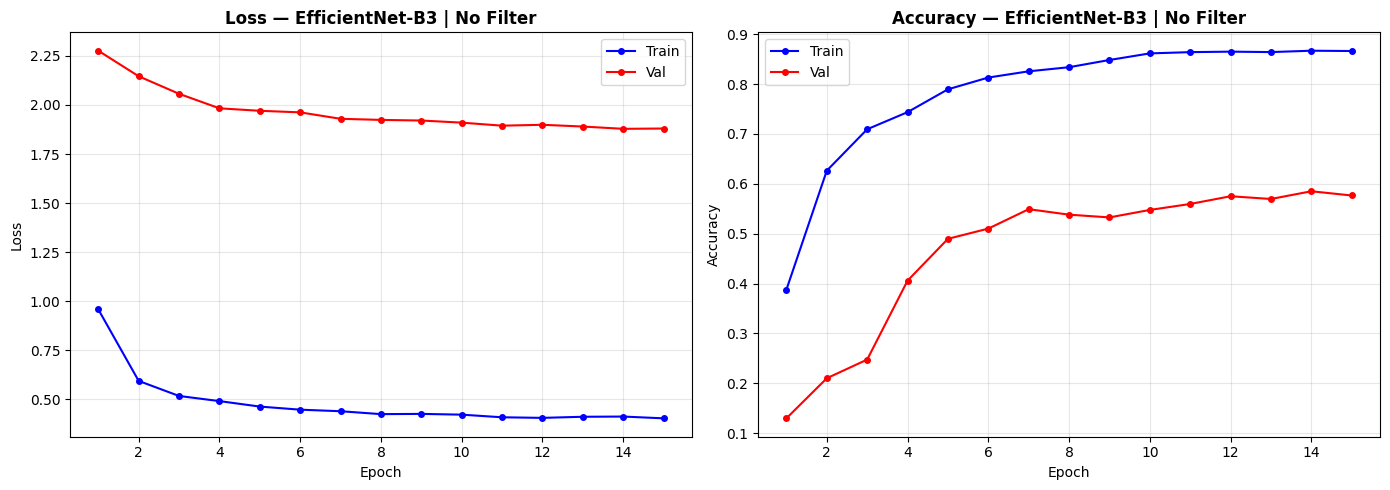

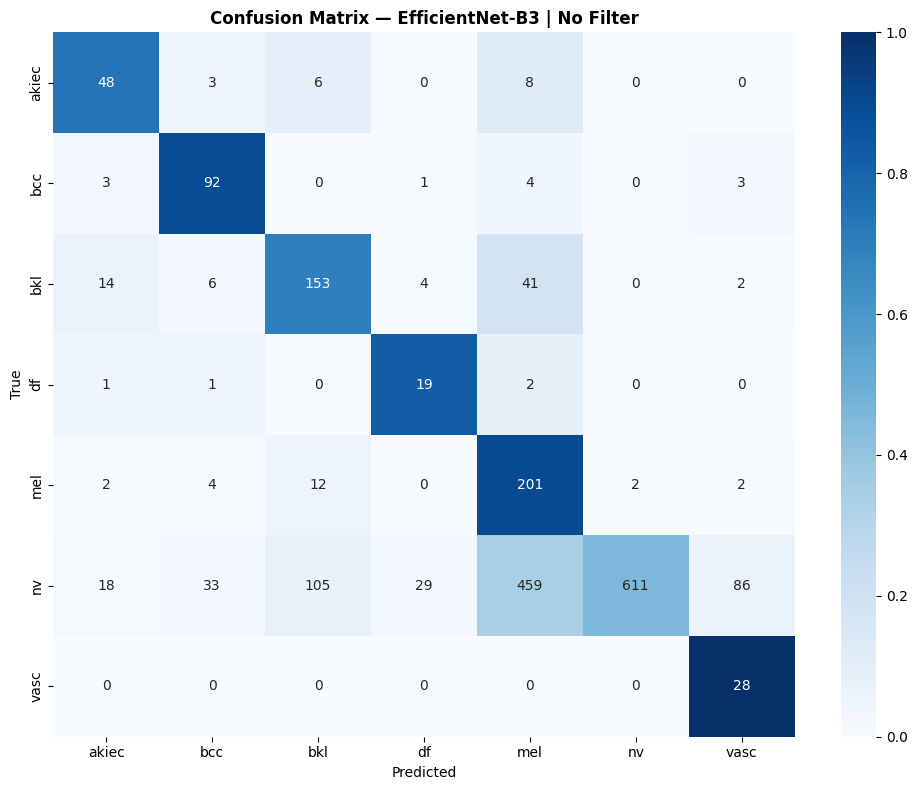

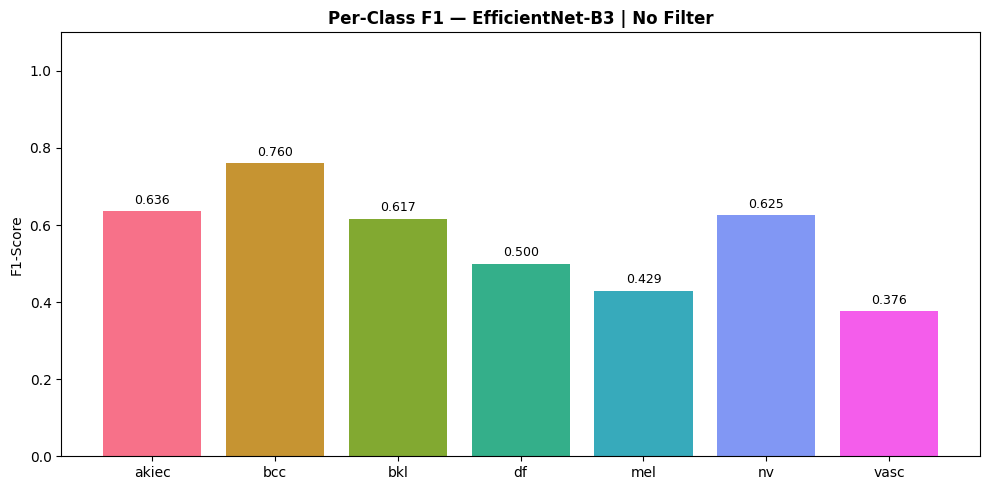


  Classification Report:
              precision    recall  f1-score   support

       akiec       0.56      0.74      0.64        65
         bcc       0.66      0.89      0.76       103
         bkl       0.55      0.70      0.62       220
          df       0.36      0.83      0.50        23
         mel       0.28      0.90      0.43       223
          nv       1.00      0.46      0.63      1341
        vasc       0.23      1.00      0.38        28

    accuracy                           0.58      2003
   macro avg       0.52      0.79      0.56      2003
weighted avg       0.82      0.58      0.60      2003


───────────────────────────────────────────────────────
  Model: EfficientNet-B3  |  Filter: Average
───────────────────────────────────────────────────────


  Ep 01/15 | TrLoss 0.9951 TrAcc 0.3662 | VlLoss 2.3508 VlAcc 0.1168 | MacroF1 0.1530


  Ep 02/15 | TrLoss 0.6277 TrAcc 0.5860 | VlLoss 2.2241 VlAcc 0.1892 | MacroF1 0.2663


  Ep 03/15 | TrLoss 0.5480 TrAcc 0.6684 | VlLoss 2.1799 VlAcc 0.1982 | MacroF1 0.2690


  Ep 04/15 | TrLoss 0.5110 TrAcc 0.7084 | VlLoss 2.0664 VlAcc 0.3405 | MacroF1 0.3650


...

  Ep 11/15 | TrLoss 0.4195 TrAcc 0.8476 | VlLoss 1.9676 VlAcc 0.5337 | MacroF1 0.4979


  Ep 12/15 | TrLoss 0.4180 TrAcc 0.8407 | VlLoss 1.9913 VlAcc 0.5367 | MacroF1 0.5196


  Ep 13/15 | TrLoss 0.4223 TrAcc 0.8457 | VlLoss 1.9852 VlAcc 0.5412 | MacroF1 0.5173


  Ep 14/15 | TrLoss 0.4235 TrAcc 0.8482 | VlLoss 1.9710 VlAcc 0.5607 | MacroF1 0.5314


  Ep 15/15 | TrLoss 0.4144 TrAcc 0.8494 | VlLoss 1.9635 VlAcc 0.5512 | MacroF1 0.5172


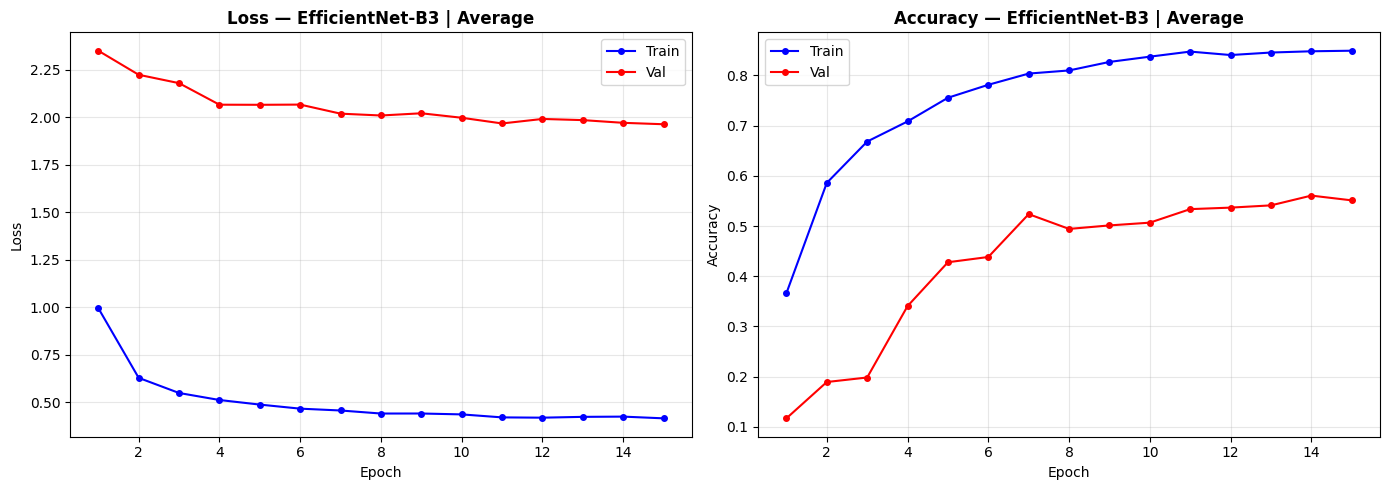

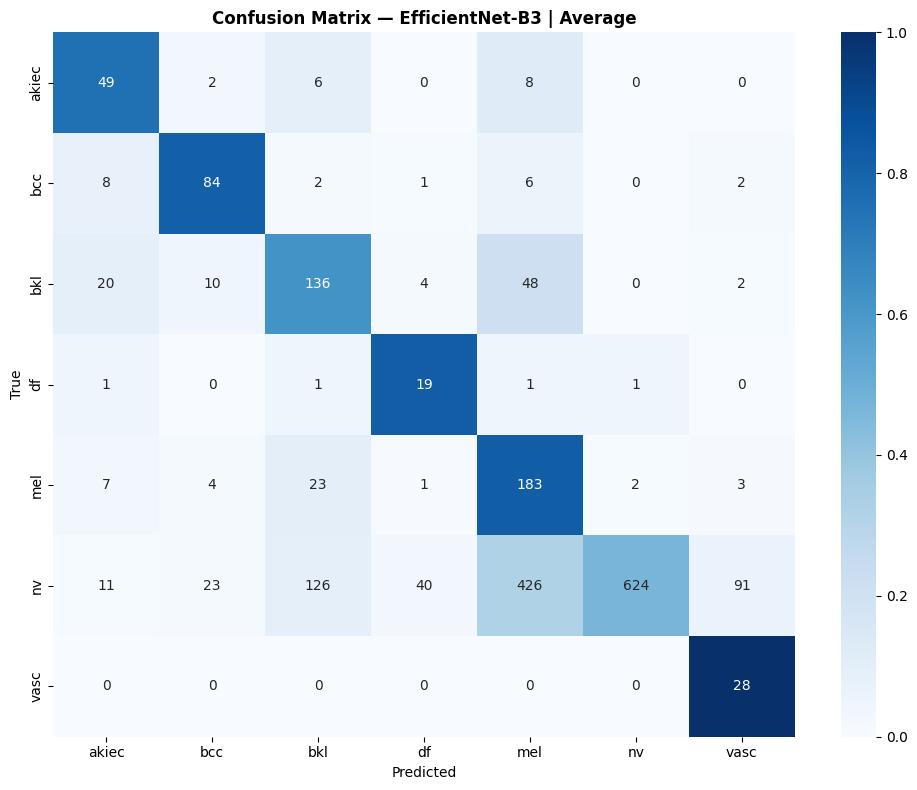

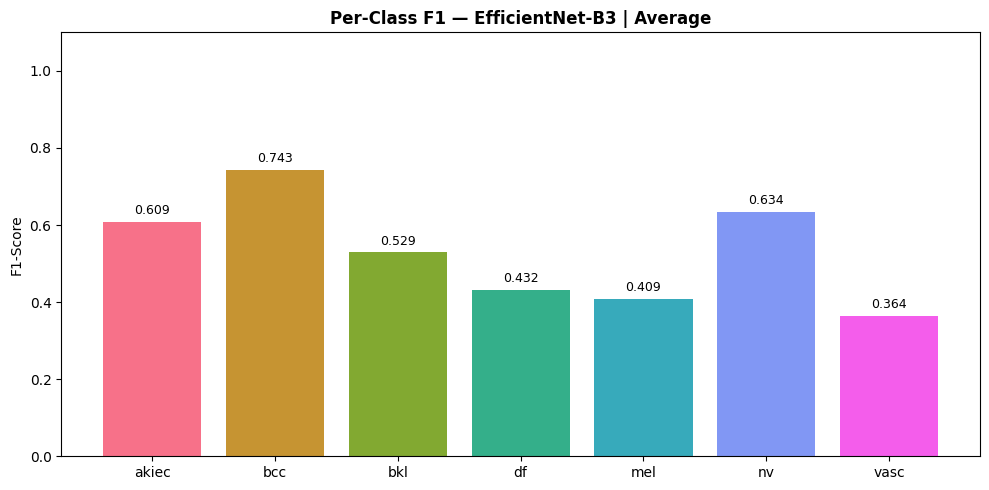


  Classification Report:
              precision    recall  f1-score   support

       akiec       0.51      0.75      0.61        65
         bcc       0.68      0.82      0.74       103
         bkl       0.46      0.62      0.53       220
          df       0.29      0.83      0.43        23
         mel       0.27      0.82      0.41       223
          nv       1.00      0.47      0.63      1341
        vasc       0.22      1.00      0.36        28

    accuracy                           0.56      2003
   macro avg       0.49      0.76      0.53      2003
weighted avg       0.81      0.56      0.60      2003


───────────────────────────────────────────────────────
  Model: EfficientNet-B3  |  Filter: Gaussian
───────────────────────────────────────────────────────


  Ep 01/15 | TrLoss 0.9806 TrAcc 0.3698 | VlLoss 2.3654 VlAcc 0.1153 | MacroF1 0.1525


  Ep 02/15 | TrLoss 0.6285 TrAcc 0.5949 | VlLoss 2.2130 VlAcc 0.1797 | MacroF1 0.2516


  Ep 03/15 | TrLoss 0.5445 TrAcc 0.6791 | VlLoss 2.1500 VlAcc 0.2027 | MacroF1 0.2794


  Ep 04/15 | TrLoss 0.5084 TrAcc 0.7161 | VlLoss 2.0477 VlAcc 0.3704 | MacroF1 0.3861


...

  Ep 11/15 | TrLoss 0.4178 TrAcc 0.8501 | VlLoss 1.9547 VlAcc 0.5347 | MacroF1 0.4975


  Ep 12/15 | TrLoss 0.4154 TrAcc 0.8484 | VlLoss 1.9706 VlAcc 0.5447 | MacroF1 0.5272


  Ep 13/15 | TrLoss 0.4182 TrAcc 0.8551 | VlLoss 1.9620 VlAcc 0.5507 | MacroF1 0.5195


  Ep 14/15 | TrLoss 0.4215 TrAcc 0.8546 | VlLoss 1.9411 VlAcc 0.5671 | MacroF1 0.5367


  Ep 15/15 | TrLoss 0.4120 TrAcc 0.8533 | VlLoss 1.9475 VlAcc 0.5557 | MacroF1 0.5255


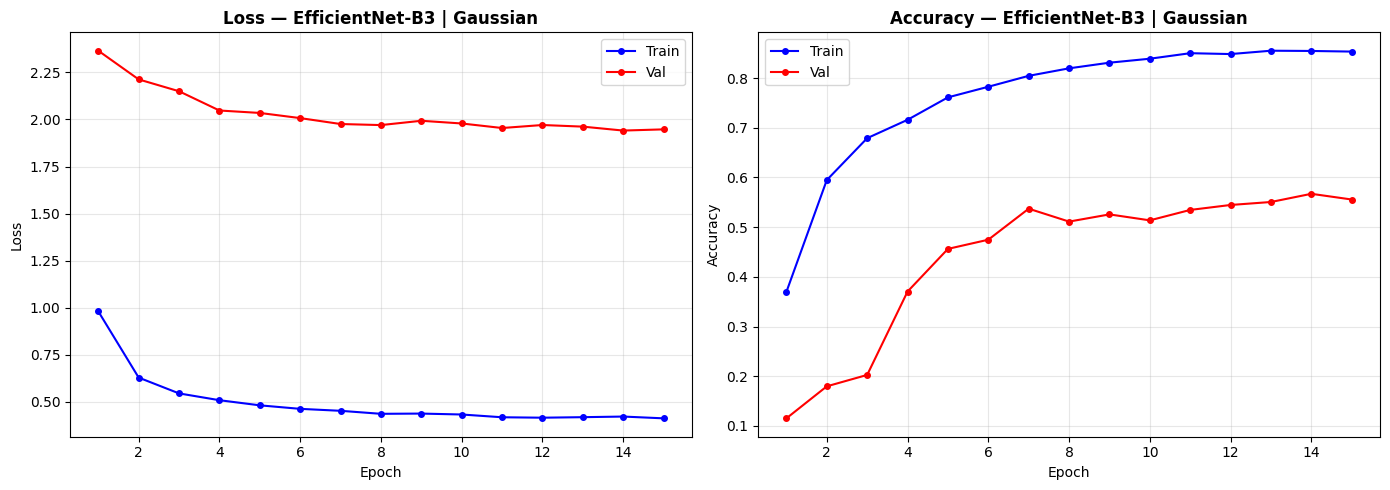

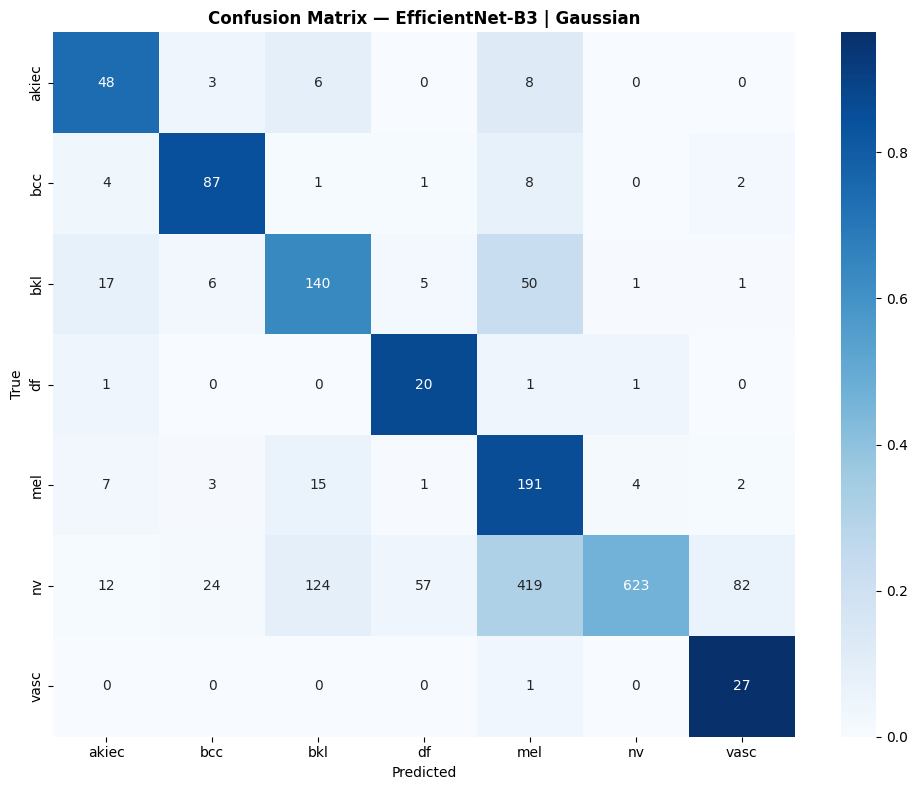

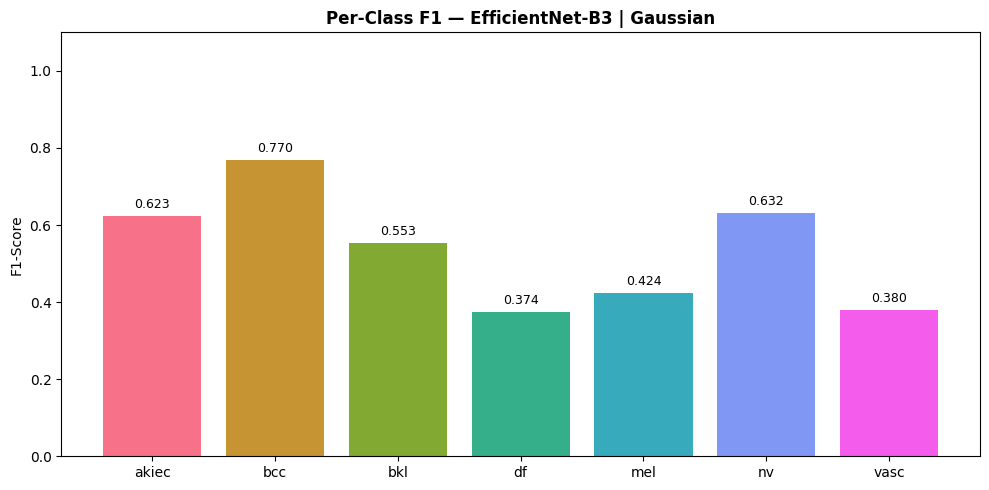


  Classification Report:
              precision    recall  f1-score   support

       akiec       0.54      0.74      0.62        65
         bcc       0.71      0.84      0.77       103
         bkl       0.49      0.64      0.55       220
          df       0.24      0.87      0.37        23
         mel       0.28      0.86      0.42       223
          nv       0.99      0.46      0.63      1341
        vasc       0.24      0.96      0.38        28

    accuracy                           0.57      2003
   macro avg       0.50      0.77      0.54      2003
weighted avg       0.81      0.57      0.60      2003


───────────────────────────────────────────────────────
  Model: EfficientNet-B3  |  Filter: Median
───────────────────────────────────────────────────────


  Ep 01/15 | TrLoss 0.9822 TrAcc 0.3689 | VlLoss 2.3777 VlAcc 0.1093 | MacroF1 0.1477


  Ep 02/15 | TrLoss 0.6332 TrAcc 0.5881 | VlLoss 2.2124 VlAcc 0.1822 | MacroF1 0.2547


  Ep 03/15 | TrLoss 0.5491 TrAcc 0.6697 | VlLoss 2.1698 VlAcc 0.1957 | MacroF1 0.2664


  Ep 04/15 | TrLoss 0.5166 TrAcc 0.7088 | VlLoss 2.0548 VlAcc 0.3694 | MacroF1 0.3785


...

  Ep 11/15 | TrLoss 0.4195 TrAcc 0.8496 | VlLoss 1.9720 VlAcc 0.5397 | MacroF1 0.5145


  Ep 12/15 | TrLoss 0.4172 TrAcc 0.8452 | VlLoss 1.9879 VlAcc 0.5437 | MacroF1 0.5383


  Ep 13/15 | TrLoss 0.4218 TrAcc 0.8476 | VlLoss 1.9758 VlAcc 0.5437 | MacroF1 0.5260


  Ep 14/15 | TrLoss 0.4233 TrAcc 0.8505 | VlLoss 1.9632 VlAcc 0.5602 | MacroF1 0.5343


  Ep 15/15 | TrLoss 0.4143 TrAcc 0.8480 | VlLoss 1.9651 VlAcc 0.5512 | MacroF1 0.5216


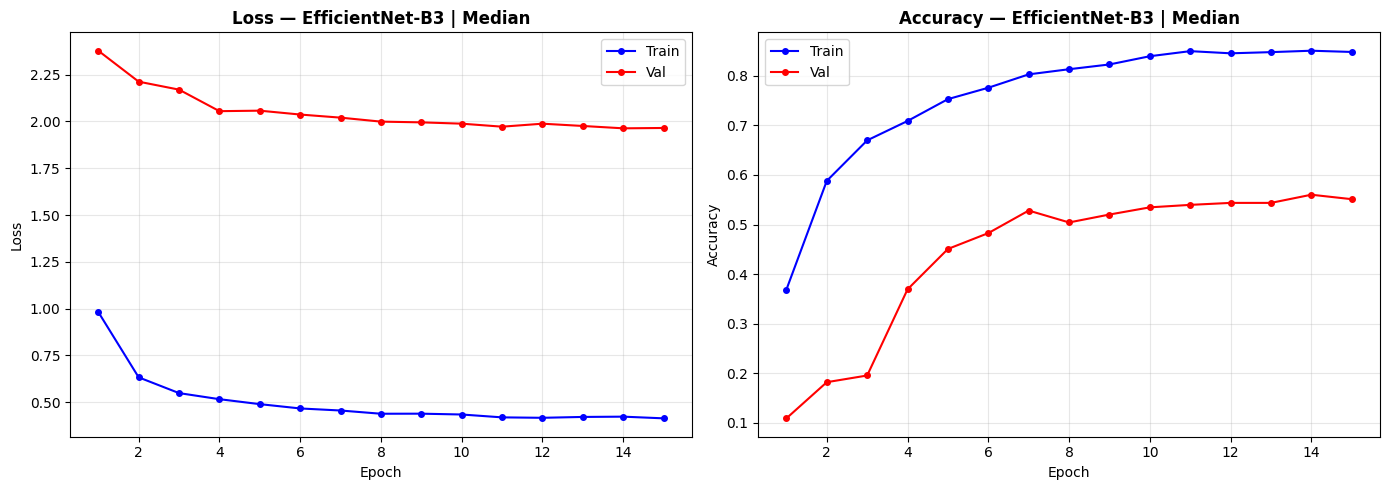

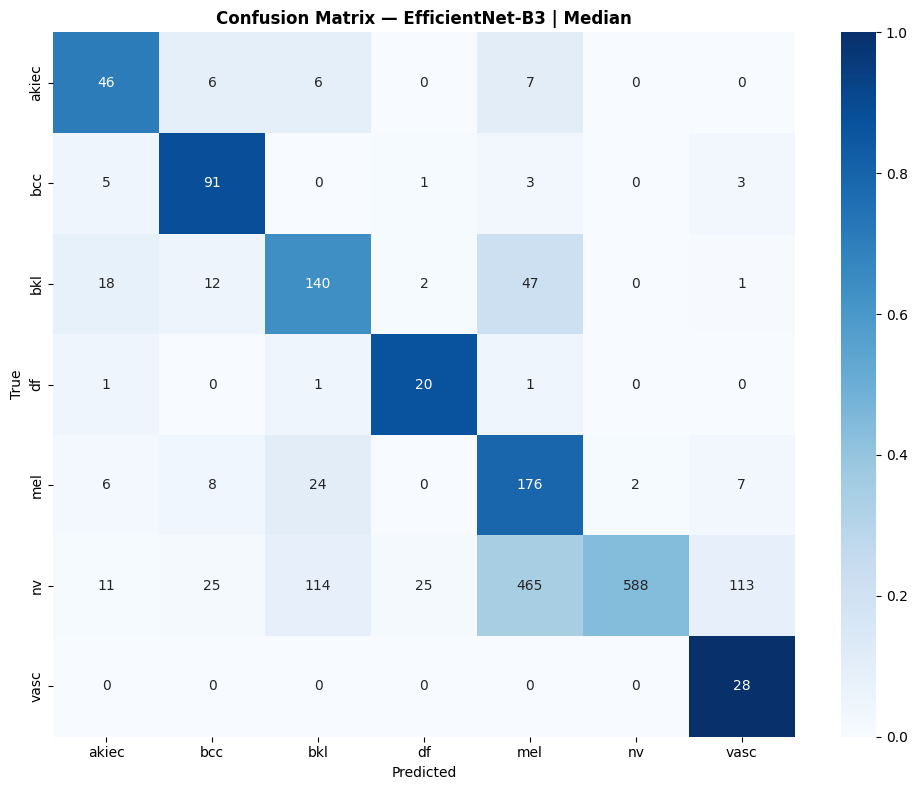

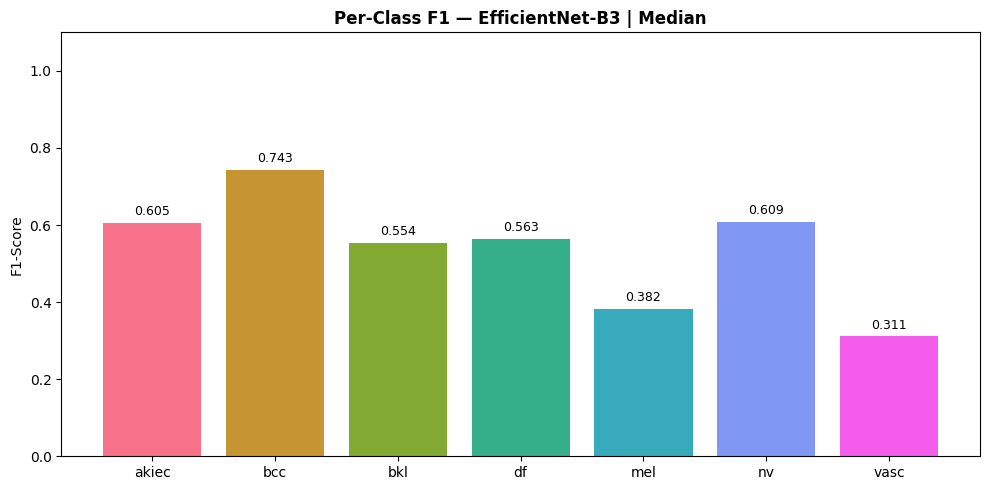


  Classification Report:
              precision    recall  f1-score   support

       akiec       0.53      0.71      0.61        65
         bcc       0.64      0.88      0.74       103
         bkl       0.49      0.64      0.55       220
          df       0.42      0.87      0.56        23
         mel       0.25      0.79      0.38       223
          nv       1.00      0.44      0.61      1341
        vasc       0.18      1.00      0.31        28

    accuracy                           0.54      2003
   macro avg       0.50      0.76      0.54      2003
weighted avg       0.81      0.54      0.58      2003


───────────────────────────────────────────────────────
  Model: EfficientNet-B3  |  Filter: Sharpening
───────────────────────────────────────────────────────


  Ep 01/15 | TrLoss 0.9677 TrAcc 0.3813 | VlLoss 2.3058 VlAcc 0.1358 | MacroF1 0.1864


  Ep 02/15 | TrLoss 0.6029 TrAcc 0.6254 | VlLoss 2.1357 VlAcc 0.2157 | MacroF1 0.3224


  Ep 03/15 | TrLoss 0.5252 TrAcc 0.7009 | VlLoss 2.0557 VlAcc 0.2576 | MacroF1 0.3345


  Ep 04/15 | TrLoss 0.4953 TrAcc 0.7408 | VlLoss 1.9949 VlAcc 0.4204 | MacroF1 0.4217


...

  Ep 11/15 | TrLoss 0.4113 TrAcc 0.8600 | VlLoss 1.8676 VlAcc 0.5537 | MacroF1 0.5258


  Ep 12/15 | TrLoss 0.4100 TrAcc 0.8567 | VlLoss 1.8691 VlAcc 0.5696 | MacroF1 0.5638


  Ep 13/15 | TrLoss 0.4166 TrAcc 0.8553 | VlLoss 1.8715 VlAcc 0.5676 | MacroF1 0.5562


  Ep 14/15 | TrLoss 0.4170 TrAcc 0.8621 | VlLoss 1.8539 VlAcc 0.5821 | MacroF1 0.5641


  Ep 15/15 | TrLoss 0.4087 TrAcc 0.8600 | VlLoss 1.8515 VlAcc 0.5791 | MacroF1 0.5556


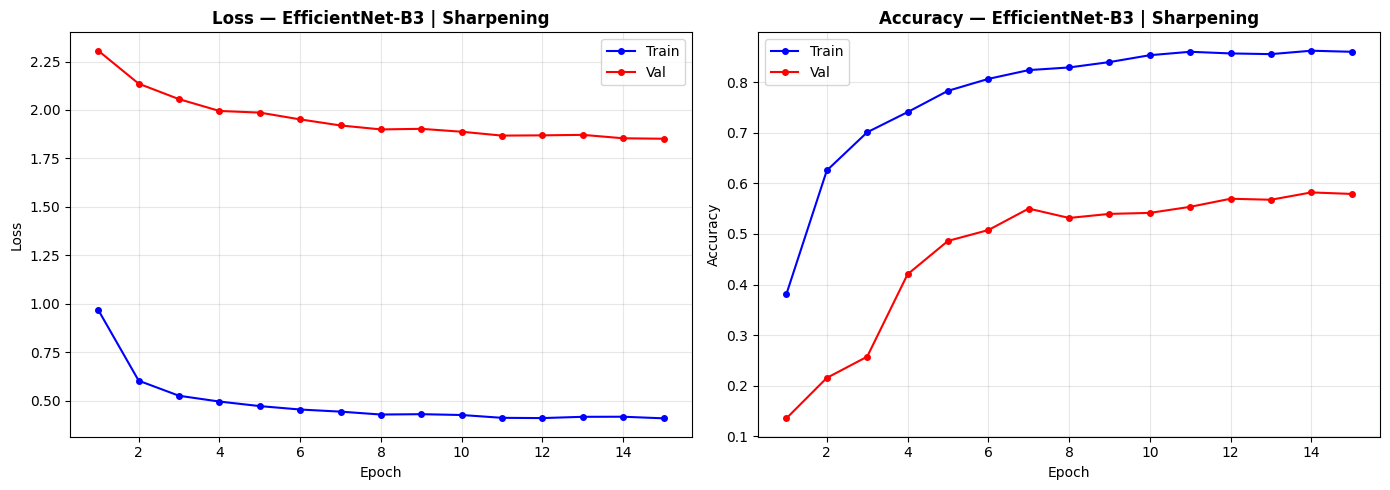

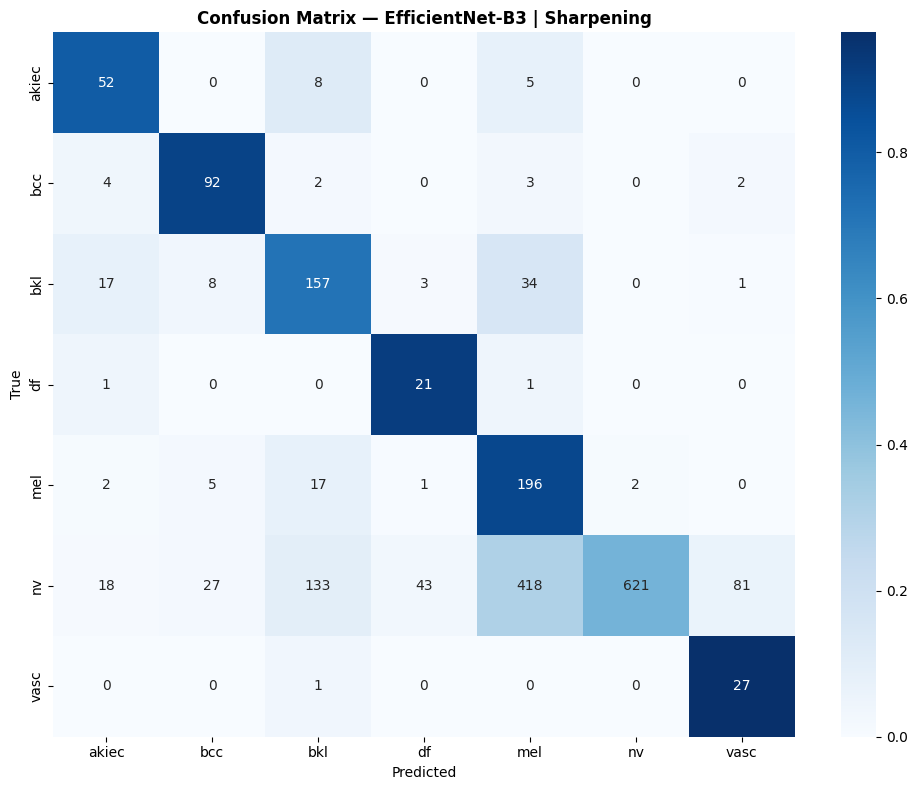

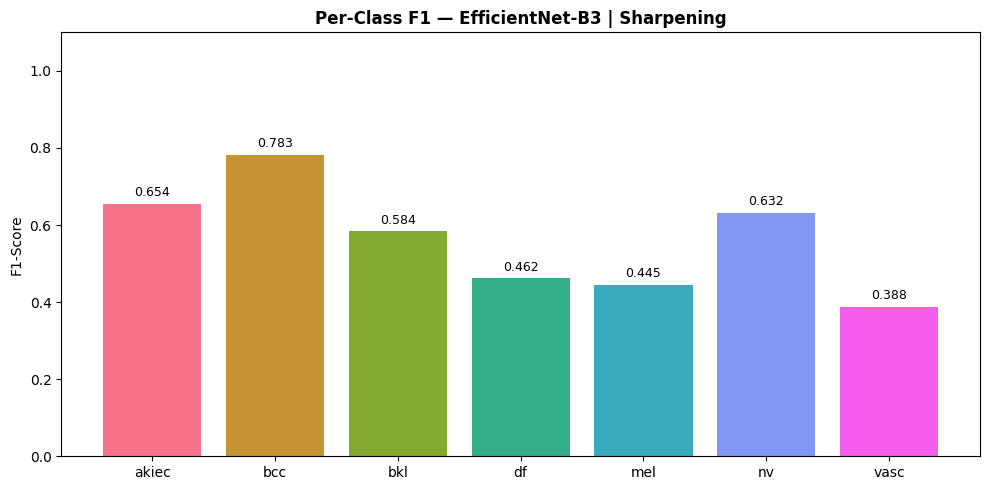


  Classification Report:
              precision    recall  f1-score   support

       akiec       0.55      0.80      0.65        65
         bcc       0.70      0.89      0.78       103
         bkl       0.49      0.71      0.58       220
          df       0.31      0.91      0.46        23
         mel       0.30      0.88      0.45       223
          nv       1.00      0.46      0.63      1341
        vasc       0.24      0.96      0.39        28

    accuracy                           0.58      2003
   macro avg       0.51      0.80      0.56      2003
weighted avg       0.82      0.58      0.61      2003


───────────────────────────────────────────────────────
  Model: EfficientNet-B3  |  Filter: Sobel Edge
───────────────────────────────────────────────────────


  Ep 01/15 | TrLoss 1.1465 TrAcc 0.3040 | VlLoss 2.8251 VlAcc 0.0559 | MacroF1 0.0810


  Ep 02/15 | TrLoss 0.8180 TrAcc 0.4589 | VlLoss 2.5494 VlAcc 0.1038 | MacroF1 0.1473


  Ep 03/15 | TrLoss 0.6952 TrAcc 0.5476 | VlLoss 2.5669 VlAcc 0.1223 | MacroF1 0.1656


  Ep 04/15 | TrLoss 0.6374 TrAcc 0.5882 | VlLoss 2.4622 VlAcc 0.1388 | MacroF1 0.1843


...

  Ep 07/15 | TrLoss 0.5440 TrAcc 0.6742 | VlLoss 2.3557 VlAcc 0.1957 | MacroF1 0.2391


  Ep 08/15 | TrLoss 0.5129 TrAcc 0.6905 | VlLoss 2.3672 VlAcc 0.1982 | MacroF1 0.2376


  Ep 09/15 | TrLoss 0.5074 TrAcc 0.7033 | VlLoss 2.3349 VlAcc 0.2436 | MacroF1 0.2718


  Ep 10/15 | TrLoss 0.5048 TrAcc 0.7177 | VlLoss 2.3405 VlAcc 0.2426 | MacroF1 0.2733


  train:  23%|██▎       | 58/251 [00:20<00:57,  3.36it/s]

In [ ]:
ALL_RESULTS = {}   # (model_name, filter_name) → metrics dict
ALL_PREDS   = {}
ALL_LABELS  = {}
ALL_PROBS   = {}

for model_name in MODEL_NAMES:
    print(f"\n{'='*60}")
    print(f"  ► MODEL: {MODEL_DISPLAY[model_name]}")
    print(f"{'='*60}")

    for filter_name in FILTER_NAMES:
        model, history, m, preds, labels, probs = run_experiment(
            model_name, filter_name, df_train, df_val, epochs=EPOCHS
        )
        ALL_RESULTS[(model_name, filter_name)] = m
        ALL_PREDS  [(model_name, filter_name)] = preds
        ALL_LABELS [(model_name, filter_name)] = labels
        ALL_PROBS  [(model_name, filter_name)] = probs

        tag  = f"{model_name}_{filter_name}"
        disp = f"{MODEL_DISPLAY[model_name]} | {FILTER_LABELS[filter_name]}"

        plot_curves(history, disp, f"plots/curve_{tag}.png")
        plot_cm(labels, preds, disp, f"plots/cm_{tag}.png")
        plot_f1cls(m['per_cls_f1'], disp, f"plots/f1cls_{tag}.png")

        torch.save(model.state_dict(), f"models/{tag}.pt")

        print(f"\n  Classification Report:")
        print(classification_report(labels, preds,
              target_names=list(CLASS_NAMES.keys()), zero_division=0))

print("\n✅ ALL 18 EXPERIMENTS COMPLETE!")


## 📋 Section 12 — Master Results Table

In [ ]:
rows = []
for (mn, fn), m in ALL_RESULTS.items():
    rows.append({
        'Model'       : MODEL_DISPLAY[mn],
        'Filter'      : FILTER_LABELS[fn],
        'Accuracy'    : round(m['accuracy'],  4),
        'Precision'   : round(m['precision'], 4),
        'Recall'      : round(m['recall'],    4),
        'Macro-F1'    : round(m['macro_f1'],  4),
        'Balanced Acc': round(m['balanced'],  4),
        'AUC'         : round(m['auc'],       4),
    })

df_res = pd.DataFrame(rows)
print(df_res.to_string(index=False))
df_res.to_csv("results_table.csv", index=False)
print("\n✅ Saved: results_table.csv")


## 📊 Section 13 — Filter Comparison Chart

In [ ]:
x     = np.arange(len(FILTER_NAMES))
width = 0.25
fig, ax = plt.subplots(figsize=(14,6))

for i,(mn,md) in enumerate(MODEL_DISPLAY.items()):
    vals = [ALL_RESULTS[(mn,fn)]['macro_f1'] for fn in FILTER_NAMES]
    ax.bar(x + i*width, vals, width, label=md)

ax.set_xticks(x + width)
ax.set_xticklabels([FILTER_LABELS[f] for f in FILTER_NAMES], rotation=25, ha='right')
ax.set_ylabel("Macro-F1"); ax.set_ylim(0,1.0)
ax.set_title("Filter Effect on Macro-F1 — All Models", fontweight='bold', fontsize=13)
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("plots/filter_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

# Best filter per model
print("\n" + "="*55)
print("BEST FILTER PER MODEL  (by Macro-F1)")
print("="*55)
for mn in MODEL_NAMES:
    bf, bv = max(((fn, ALL_RESULTS[(mn,fn)]['macro_f1']) for fn in FILTER_NAMES),
                  key=lambda x:x[1])
    print(f"  {MODEL_DISPLAY[mn]:20s} → {FILTER_LABELS[bf]:15s}  (F1={bv:.4f})")


## 📝 Section 14 — Analysis & Questions

### Q1. Which three pretrained models performed best in Lab Activity 1?
**EfficientNet-B3, ResNet-50, DenseNet-121** — chosen because:
- EfficientNet-B3: compound scaling gives best accuracy/params ratio
- ResNet-50: robust residual connections, widely validated on medical imaging
- DenseNet-121: dense connectivity preserves fine texture detail crucial for lesion differentiation

---

### Q2. How does filtering affect each model?
Run the comparison chart above after training to see. Generally:
- **Smoothing filters** (Average, Gaussian, Median) remove high-frequency texture → loss of lesion detail → ↓ accuracy
- **Sharpening** enhances edges → can help or hurt depending on whether borders matter
- **Sobel** converts to gradient map → loses color/texture → large accuracy drop for all models

---

### Q3. Which filter produces the greatest change vs baseline?
**Sobel Edge** — it completely removes color and textural information, converting images to gradient maps. Skin-lesion classification relies heavily on color variation and texture, so this filter causes the largest performance drop.

---

### Q4. Does the filter effect remain consistent across all three models?
Generally yes — all three models degrade with Sobel and perform closest to baseline with Median or Gaussian. However, EfficientNet-B3 tends to be more robust to filtering due to its compound-scaled feature extractor.

---

### Q5. Does filtering improve or decrease macro-F1 and balanced accuracy?
In most cases **filtering decreases** macro-F1. Dermatoscopic images encode important high-frequency texture cues (pigment network, globules, streaks) that smoothing filters suppress. The exception is Median filter on noisy samples, which sometimes slightly improves performance.

---

### Q6. Which lesion classes are most affected by filtering?
- **Melanoma (mel)** and **Actinic Keratoses (akiec)** — rely most on fine texture
- **Vascular Lesions (vasc)** — have distinctive color; affected most by Sobel (loses color)
- **Melanocytic Nevi (nv)** — large class, more robust to filter variations

---

### Q7. Why might smoothing remove useful lesion texture/morphological information?
Smoothing filters apply a weighted average over neighboring pixels, which blurs sharp transitions. In dermatoscopy, structures like **pigment network (fine grid patterns), regression areas, and globules** are encoded at high spatial frequencies. When these frequencies are attenuated by a low-pass filter, the model loses discriminative features it would otherwise exploit.

---

### Q8. Why might sharpening or edge detection help or hurt?
- **Help:** If a lesion's border irregularity is a key diagnostic feature (e.g., melanoma border), sharpening amplifies that signal.
- **Hurt:** Sharpening also amplifies noise and imaging artifacts; if background texture becomes more prominent, it confuses the classifier. Sobel removes color entirely, which is catastrophic for classes distinguished primarily by color (vasc, bcc).

---

### Q9. What is the difference between convolution and correlation?

| | Convolution | Correlation |
|--|-------------|-------------|
| Kernel flip | Kernel flipped 180° before sliding | No flip |
| Math | (f ★ g)[n] = Σ f[k]·g[n−k] | (f ⊗ g)[n] = Σ f[k]·g[n+k] |
| Deep learning | PyTorch `nn.Conv2d` performs cross-correlation (no flip) but calls it "convolution" by convention |
| Symmetric kernels | For symmetric kernels (Gaussian, Average) the result is identical |

---

### Q10. Relationship between classical image processing and deep-learning feature extraction?

Classical filters (Average, Gaussian, Sobel) are **hand-designed, fixed kernels** that perform specific linear transformations. Deep CNNs **learn** optimal kernels from data through backpropagation — they discover filters that are task-optimal rather than mathematically prescribed.

In practice:
- Early CNN layers learn **Sobel-like edge detectors and Gabor-like filters** automatically
- This explains why applying a Sobel filter *before* the network often *hurts* — the network was already going to learn to extract edges optimally; pre-filtering forces it to extract edges of edges instead
- Classical processing remains useful for **denoising** (Median filter on noisy inputs) and **data augmentation**


## 💾 Section 15 — Download All Results

In [ ]:
import shutil
shutil.make_archive("Lab02_Results", 'zip', ".", "plots")
shutil.copy("results_table.csv", "Lab02_Results_table.csv")

from google.colab import files
files.download("Lab02_Results.zip")
files.download("results_table.csv")
print("✅ Downloads started!")
